# Análise exploratória do Ensino Médio — pôster de Inglês

**INEP | 2011–2025**

Este notebook foi organizado em torno dos três blocos definidos para o pôster:

1. **Expansão do Ensino Médio integral:** evolução da proporção de escolas integrais nas cinco regiões brasileiras.
2. **Perfis das taxas de rendimento:** distribuições de reprovação e abandono por modalidade e dependência administrativa.
3. **Associação por ano e dependência:** correlação de Spearman entre a proporção de matrículas integrais e as taxas de reprovação e abandono.

A ideia é produzir três figuras principais, tabelas de apoio e arquivos CSV para documentar os resultados.

> **Importante:** este notebook não estima efeito causal. Ele descreve distribuições e associações nos dados observados.

### Decisões metodológicas configuráveis

- A modalidade é classificada pela proporção de matrículas integrais da escola-ano. O padrão abaixo usa **10% e 90%**: Regular se `p ≤ 0,10`; Mista se `0,10 < p < 0,90`; Integral se `p ≥ 0,90`.
- A expansão regional considera, por padrão, escolas das dependências **Estadual e Municipal**, agrupadas. Isso é coerente com o recorte do abstract sobre a expansão nessas redes.
- Nos boxplots, a unidade é **escola × modalidade observada no período**. Se uma escola muda de modalidade, ela pode contribuir com uma unidade para cada modalidade em que apareceu.
- As taxas de rendimento usam o denominador `APR + REP + ABA`, conforme a definição do INEP. A soma das três taxas (aprovação, reprovação e abandono) é 100% quando os três quantitativos estão disponíveis.
- Para reduzir taxas muito instáveis de escolas muito pequenas, há um corte configurável de 30 matrículas de oferta por escola-ano (ou média anual por unidade escola-modalidade nos boxplots).

**Antes de interpretar os resultados:** confira as tabelas de qualidade e as categorias originais de `DEP_ADM` e `REGIAO`. A correção da classificação precisa estar refletida na base `bd5` usada nesta execução.

## 0. Configuração, leitura e preparação

In [11]:
from pathlib import Path
import re
import unicodedata
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# ------------------------------------------------------------------
# CONFIGURAÇÕES — ajuste aqui se a equipe decidir outro critério
# ------------------------------------------------------------------
ANO_INICIAL = 2011
ANO_FINAL = 2025
TOL_MODALIDADE = 0.10       # Regular: p <= 10%; Integral: p >= 90%; Mista: entre elas
MIN_MATRICULAS_ANO = 30     # filtro de porte para boxplots e correlações
MIN_N_SPEARMAN = 30         # mínimo de escolas para calcular Spearman por ano/rede

# Para manter o recorte do abstract: expansão nas redes estadual + municipal.
# Para incluir todas as dependências, altere para: ["Estadual/Municipal"]
DEPENDENCIAS_EXPANSAO = ["Federal", "Estadual/Municipal", "Privada"] 

SEPARADOR_CSV = ";"
ENCODING_CSV = "utf-8-sig"

ORDEM_MODALIDADE = ["Regular", "Mista", "Integral"]
ORDEM_DEPENDENCIA = ["Federal", "Estadual/Municipal", "Privada"]
ORDEM_REGIAO = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]

COR_MODALIDADE = {"Regular": "#2a78d6", "Mista": "#eb6834", "Integral": "#1baf7a"}
COR_DEPENDENCIA = {"Federal": "#6250d6", "Estadual/Municipal": "#008f72", "Privada": "#d95f59"}
COR_REGIAO = {
    "Norte": "#4477AA", "Nordeste": "#EE6677", "Centro-Oeste": "#228833",
    "Sudeste": "#CCBB44", "Sul": "#66CCEE"
}

# Localiza a raiz do projeto procurando a pasta 01. Dados nos diretórios atuais/pais.
def encontrar_raiz_projeto(inicio=Path.cwd()):
    for candidato in [inicio, *inicio.parents]:
        if (candidato / "01. Dados").is_dir():
            return candidato
    return inicio

RAIZ_PROJETO = encontrar_raiz_projeto()

CAMINHO_BASE = None

if CAMINHO_BASE is None:
    candidatos = [
        RAIZ_PROJETO / "01. Dados" / "bd8.zip",
        RAIZ_PROJETO / "01. Dados" / "bd8.csv",
        RAIZ_PROJETO / "Dados" / "bd8.zip",
        RAIZ_PROJETO / "Dados" / "bd8.csv",
        RAIZ_PROJETO / "bd5.zip",
        RAIZ_PROJETO / "bd5.csv",
    ]
    CAMINHO_BASE = next((p for p in candidatos if p.exists()), None)
else:
    CAMINHO_BASE = Path(CAMINHO_BASE)

if CAMINHO_BASE is None or not CAMINHO_BASE.exists():
    raise FileNotFoundError(
        "Não encontrei bd8.zip ou bd8.csv. Coloque o arquivo em '01. Dados' "
        "ou informe manualmente CAMINHO_BASE na célula de configuração.\n"
        f"Raiz identificada: {RAIZ_PROJETO}"
    )

PASTA_RESULTADOS = RAIZ_PROJETO / "03. Resultados" / "Poster_3_analises"
PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 250,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e5e5e5",
    "grid.linewidth": 0.7,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "legend.frameon": False,
})

print(f"Raiz do projeto: {RAIZ_PROJETO}")
print(f"Base selecionada: {CAMINHO_BASE}")
print(f"Resultados serão salvos em: {PASTA_RESULTADOS}")
print(f"Classificação: Regular ≤ {TOL_MODALIDADE:.0%}; Integral ≥ {1-TOL_MODALIDADE:.0%}; Mista entre os limites.")


Raiz do projeto: c:\Users\Yasmin\IMPA TECH\2º. ano\2.2\PICME\Fase1\ED-Dados-INEP
Base selecionada: c:\Users\Yasmin\IMPA TECH\2º. ano\2.2\PICME\Fase1\ED-Dados-INEP\01. Dados\bd8.zip
Resultados serão salvos em: c:\Users\Yasmin\IMPA TECH\2º. ano\2.2\PICME\Fase1\ED-Dados-INEP\03. Resultados\Poster_3_analises
Classificação: Regular ≤ 10%; Integral ≥ 90%; Mista entre os limites.


### 0.1. Leitura dos dados e padronização das categorias

O arquivo pode ser `bd5.zip` ou `bd5.csv`. O código lê somente as colunas necessárias para as três análises. A tabela deve conter uma linha por escola-ano; duplicatas nessa chave são sinalizadas para evitar contagens ou pesos duplicados.

In [12]:
COLUNAS_ORIGINAIS = [
    "ANO", "CO_ESCOLA", "UF", "REGIAO", "LOCALIZACAO", "DEP_ADM",
    "QT_MAT_EM_REG", "QT_MAT_EM_INT",
    "QT_APR_EM_TOTAL", "QT_REP_EM_TOTAL", "QT_ABN_EM_TOTAL",
]


def ler_csv_ou_zip(caminho):
    """Lê bd8.csv ou o CSV contido em bd8.zip, mantendo somente as colunas necessárias."""
    caminho = Path(caminho)
    if caminho.suffix.lower() == ".zip":
        with zipfile.ZipFile(caminho) as zf:
            membros = [n for n in zf.namelist() if n.lower().endswith(".csv")]
            if not membros:
                raise FileNotFoundError("O ZIP não contém nenhum arquivo CSV.")
            exatos = [n for n in membros if Path(n).name.lower() == "bd8.csv"]
            if len(exatos) == 1:
                membro = exatos[0]
            elif len(membros) == 1:
                membro = membros[0]
            else:
                raise ValueError(
                    "O ZIP contém mais de um CSV e nenhum se chama bd8.csv. "
                    f"Arquivos encontrados: {membros}"
                )
            with zf.open(membro) as arquivo:
                cabecalho = pd.read_csv(arquivo, sep=SEPARADOR_CSV, encoding=ENCODING_CSV, nrows=0)
            nomes = [str(c).strip() for c in cabecalho.columns]
            faltantes = sorted(set(COLUNAS_ORIGINAIS) - set(nomes))
            if faltantes:
                raise ValueError(f"Colunas ausentes no CSV dentro do ZIP: {faltantes}")
            with zf.open(membro) as arquivo:
                dados = pd.read_csv(
                    arquivo, sep=SEPARADOR_CSV, encoding=ENCODING_CSV,
                    usecols=lambda c: str(c).strip() in COLUNAS_ORIGINAIS,
                    low_memory=False,
                )
    elif caminho.suffix.lower() == ".csv":
        cabecalho = pd.read_csv(caminho, sep=SEPARADOR_CSV, encoding=ENCODING_CSV, nrows=0)
        nomes = [str(c).strip() for c in cabecalho.columns]
        faltantes = sorted(set(COLUNAS_ORIGINAIS) - set(nomes))
        if faltantes:
            raise ValueError(f"Colunas ausentes no CSV: {faltantes}")
        dados = pd.read_csv(
            caminho, sep=SEPARADOR_CSV, encoding=ENCODING_CSV,
            usecols=lambda c: str(c).strip() in COLUNAS_ORIGINAIS,
            low_memory=False,
        )
    else:
        raise ValueError("A base deve ser um arquivo .zip ou .csv.")
    dados.columns = dados.columns.astype(str).str.strip()
    return dados


def normalizar_texto(valor):
    if pd.isna(valor):
        return ""
    texto = str(valor).strip().lower()
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")
    texto = re.sub(r"\s+", " ", texto)
    return texto


def classificar_dependencia(valor):
    s = normalizar_texto(valor)
    if s in {"1", "1.0", "federal"} or "federal" in s:
        return "Federal"
    if s in {"2", "2.0", "3", "3.0", "estadual", "municipal"}:
        return "Estadual/Municipal"
    if "estadual" in s or "municipal" in s:
        return "Estadual/Municipal"
    if s in {"4", "4.0", "privada", "privado"} or "privad" in s:
        return "Privada"
    return pd.NA


def classificar_regiao(valor):
    s = normalizar_texto(valor)
    mapa = {
        "1": "Norte", "1.0": "Norte", "n": "Norte", "norte": "Norte",
        "2": "Nordeste", "2.0": "Nordeste", "ne": "Nordeste", "nordeste": "Nordeste",
        "3": "Sudeste", "3.0": "Sudeste", "se": "Sudeste", "sudeste": "Sudeste",
        "4": "Sul", "4.0": "Sul", "s": "Sul", "sul": "Sul",
        "5": "Centro-Oeste", "5.0": "Centro-Oeste", "co": "Centro-Oeste",
        "centro-oeste": "Centro-Oeste", "centro oeste": "Centro-Oeste", "centrooeste": "Centro-Oeste",
    }
    return mapa.get(s, pd.NA)


bruto = ler_csv_ou_zip(CAMINHO_BASE)
bruto = bruto.rename(columns={
    "ANO": "ano", "CO_ESCOLA": "escola", "UF": "uf", "REGIAO": "regiao_original",
    "LOCALIZACAO": "localizacao", "DEP_ADM": "dependencia_original",
    "QT_MAT_EM_REG": "mat_reg", "QT_MAT_EM_INT": "mat_int",
    "QT_APR_EM_TOTAL": "apr", "QT_REP_EM_TOTAL": "rep", "QT_ABN_EM_TOTAL": "abn",
})

for coluna in ["ano", "mat_reg", "mat_int", "apr", "rep", "abn"]:
    bruto[coluna] = pd.to_numeric(bruto[coluna], errors="coerce")
bruto["escola"] = pd.to_numeric(bruto["escola"], errors="coerce").astype("Int64").astype("string")

# Mantém o intervalo definido no estudo.
bruto = bruto[bruto["ano"].between(ANO_INICIAL, ANO_FINAL)].copy()
bruto["ano"] = bruto["ano"].astype("Int64")
bruto["dependencia"] = bruto["dependencia_original"].map(classificar_dependencia)
bruto["regiao"] = bruto["regiao_original"].map(classificar_regiao)

# Diagnóstico da classificação original: confira especialmente categorias não reconhecidas.
print("Valores originais de DEP_ADM:")
display(bruto["dependencia_original"].value_counts(dropna=False).to_frame("registros"))
print("Valores de DEP_ADM após padronização:")
display(bruto["dependencia"].value_counts(dropna=False).to_frame("registros"))
print("Valores originais de REGIAO:")
display(bruto["regiao_original"].value_counts(dropna=False).to_frame("registros"))
print("Valores de REGIAO após padronização:")
display(bruto["regiao"].value_counts(dropna=False).to_frame("registros"))

# Uma linha por escola-ano é necessária para os cálculos e para as correlações anuais.
duplicadas = bruto.duplicated(["escola", "ano"], keep=False)
if duplicadas.any():
    amostra = bruto.loc[duplicadas, ["escola", "ano", "dependencia_original", "regiao_original"]].head(20)
    display(amostra)
    raise ValueError(
        f"Foram encontradas {int(duplicadas.sum())} linhas em chaves escola-ano duplicadas. "
        "Investigue a base antes de continuar; o notebook não remove duplicatas automaticamente."
    )

print(f"\nLinhas lidas no período {ANO_INICIAL}–{ANO_FINAL}: {len(bruto):,}".replace(",", "."))


Valores originais de DEP_ADM:


,registros
dependencia_original,
Municipal,1252756
Estadual,433425
Privada,357424
Federal,8026


Valores de DEP_ADM após padronização:


,registros
dependencia,
Estadual/Municipal,1686181
Privada,357424
Federal,8026


Valores originais de REGIAO:


,registros
regiao_original,
Nordeste,838614
Sudeste,561679
Norte,303318
Sul,233667
Centro-Oeste,114353


Valores de REGIAO após padronização:


,registros
regiao,
Nordeste,838614
Sudeste,561679
Norte,303318
Sul,233667
Centro-Oeste,114353



Linhas lidas no período 2011–2025: 2.051.631


### 0.2. Construção da modalidade e das taxas de rendimento

A proporção `p_int` é calculada a partir das matrículas regulares e integrais da escola-ano:

\[p_{int}=\frac{\text{matrículas integrais}}{\text{matrículas regulares}+\text{matrículas integrais}}.\]

Para as taxas de rendimento, o denominador é:

\[
D=APR+REP+ABA,
\qquad T_{rep}=\frac{REP}{D}\times100,
\qquad T_{aban} = \frac{ABA}{D}\times100.
\]

A classificação da modalidade é uma regra operacional do estudo, enquanto o denominador das taxas segue a metodologia do INEP. As taxas só são calculadas quando os três quantitativos (`APR`, `REP`, `ABA`) estão informados e o denominador é positivo.

In [13]:
if not (0 <= TOL_MODALIDADE < 0.5):
    raise ValueError("TOL_MODALIDADE deve estar entre 0 e 0,5 (exclusive).")

# Para classificar modalidade, exigimos que as duas parcelas de matrícula estejam informadas.
valid_matriculas = (
    bruto["escola"].notna()
    & bruto["ano"].notna()
    & bruto["mat_reg"].notna()
    & bruto["mat_int"].notna()
    & (bruto["mat_reg"] >= 0)
    & (bruto["mat_int"] >= 0)
)
base = bruto.loc[valid_matriculas].copy()
base["mat_oferta"] = base["mat_reg"] + base["mat_int"]
base = base[base["mat_oferta"] > 0].copy()
base["p_int"] = base["mat_int"] / base["mat_oferta"]

base["modalidade"] = np.select(
    [base["p_int"] <= TOL_MODALIDADE, base["p_int"] >= 1 - TOL_MODALIDADE],
    ["Regular", "Integral"],
    default="Mista",
)
base["modalidade"] = pd.Categorical(base["modalidade"], categories=ORDEM_MODALIDADE, ordered=True)
base["dependencia"] = pd.Categorical(base["dependencia"], categories=ORDEM_DEPENDENCIA)
base["regiao"] = pd.Categorical(base["regiao"], categories=ORDEM_REGIAO)

# A taxa oficial usa APR + REP + ABA; não substitua esse denominador por mat_reg + mat_int.
valid_rendimento = (
    base[["apr", "rep", "abn"]].notna().all(axis=1)
    & (base[["apr", "rep", "abn"]] >= 0).all(axis=1)
)
rendimento = base.loc[valid_rendimento].copy()
rendimento["den_rendimento"] = rendimento["apr"] + rendimento["rep"] + rendimento["abn"]
rendimento = rendimento[rendimento["den_rendimento"] > 0].copy()
rendimento["tx_apr"] = rendimento["apr"] / rendimento["den_rendimento"] * 100
rendimento["tx_rep"] = rendimento["rep"] / rendimento["den_rendimento"] * 100
rendimento["tx_abn"] = rendimento["abn"] / rendimento["den_rendimento"] * 100

print(f"Escolas-ano com matrículas válidas para classificar modalidade: {len(base):,}".replace(",", "."))
print(f"Escolas-ano com APR, REP e ABA válidos: {len(rendimento):,}".replace(",", "."))
print(f"Escolas distintas na base de modalidade: {base['escola'].nunique():,}".replace(",", "."))
print(f"Escolas distintas com rendimento válido: {rendimento['escola'].nunique():,}".replace(",", "."))
print(f"Registros excluídos por falta de matrícula válida: {len(bruto) - len(base):,}".replace(",", "."))
print(f"Registros sem os três quantitativos de rendimento válidos: {len(base) - len(rendimento):,}".replace(",", "."))

# Verificação: aprovação + reprovação + abandono deve somar 100% (salvo arredondamento numérico).
soma_taxas = rendimento["tx_apr"] + rendimento["tx_rep"] + rendimento["tx_abn"]
print(f"Maior desvio de 100% na soma das taxas: {(soma_taxas - 100).abs().max():.10f} p.p.")

print("\nContagem de escolas-ano por dependência × modalidade:")
display(pd.crosstab(rendimento["dependencia"], rendimento["modalidade"], margins=True, margins_name="Total"))

# Diagnóstico de dependência/região não reconhecida. Não são incorporadas aos recortes por categoria.
print("\nRegistros sem dependência padronizada:", int(base["dependencia"].isna().sum()))
print("Registros sem região padronizada:", int(base["regiao"].isna().sum()))


# Checagem de continuidade da classificação Federal em 2024–2025.
# O notebook anterior levantou uma possível mudança de registro nesse grupo; não excluímos 2025 automaticamente.
federal = base[base["dependencia"] == "Federal"]
fed_2024 = federal[federal["ano"] == 2024].set_index("escola")[["modalidade", "p_int"]]
fed_2025 = federal[federal["ano"] == 2025].set_index("escola")[["modalidade", "p_int"]]
if not fed_2024.empty and not fed_2025.empty:
    fed_par = fed_2024.join(fed_2025, lsuffix="_2024", rsuffix="_2025", how="inner")
    print("\nChecagem Federal: escolas presentes em 2024 e 2025:", len(fed_par))
    display(pd.crosstab(fed_par["modalidade_2024"], fed_par["modalidade_2025"], margins=True))
    mudaram_de_integral = fed_par[
        (fed_par["modalidade_2024"] == "Integral")
        & (fed_par["modalidade_2025"] != "Integral")
    ]
    print("Escolas integrais em 2024 que deixaram de ser integrais em 2025:", len(mudaram_de_integral))
    if len(mudaram_de_integral):
        print("Resumo de p_int em 2025 para esse grupo:")
        display(mudaram_de_integral["p_int_2025"].describe().to_frame("p_int_2025"))
else:
    print("Checagem Federal 2024–2025 não executada: um dos anos não está disponível.")


Escolas-ano com matrículas válidas para classificar modalidade: 429.001
Escolas-ano com APR. REP e ABA válidos: 426.128
Escolas distintas na base de modalidade: 37.039
Escolas distintas com rendimento válido: 36.851
Registros excluídos por falta de matrícula válida: 1.622.630
Registros sem os três quantitativos de rendimento válidos: 2.873
Maior desvio de 100% na soma das taxas: 0.0000000000 p.p.

Contagem de escolas-ano por dependência × modalidade:


modalidade,Regular,Mista,Integral,Total
dependencia,,,,
Federal,3872,807,2974,7653
Estadual/Municipal,241963,26961,26740,295664
Privada,114357,2924,5530,122811
Total,360192,30692,35244,426128



Registros sem dependência padronizada: 0
Registros sem região padronizada: 0

Checagem Federal: escolas presentes em 2024 e 2025: 610


modalidade_2025,Regular,Mista,Integral,All
modalidade_2024,,,,
Regular,227,27,5,259
Mista,12,33,8,53
Integral,24,66,208,298
All,263,126,221,610


Escolas integrais em 2024 que deixaram de ser integrais em 2025: 90
Resumo de p_int em 2025 para esse grupo:


,p_int_2025
count,90.000000
mean,0.382112
std,0.310614
min,0.000000
25%,0.027071
50%,0.359240
75%,0.681638
max,0.889610


---

# 01. The expansion of full-time high schools

**Pergunta:** a proporção de escolas estaduais/municipais com Ensino Médio classificadas como integrais cresceu entre 2011 e 2025? Esse crescimento ocorreu de maneira semelhante nas cinco regiões?

**Unidade:** escola-ano. Em cada ano e região, o percentual é a quantidade de escolas integrais dividida pelo total de escolas estaduais/municipais com Ensino Médio e informação válida de matrículas regulares e integrais.

O gráfico usa a proporção, e não a quantidade absoluta de escolas, para permitir a comparação entre regiões de tamanhos diferentes.

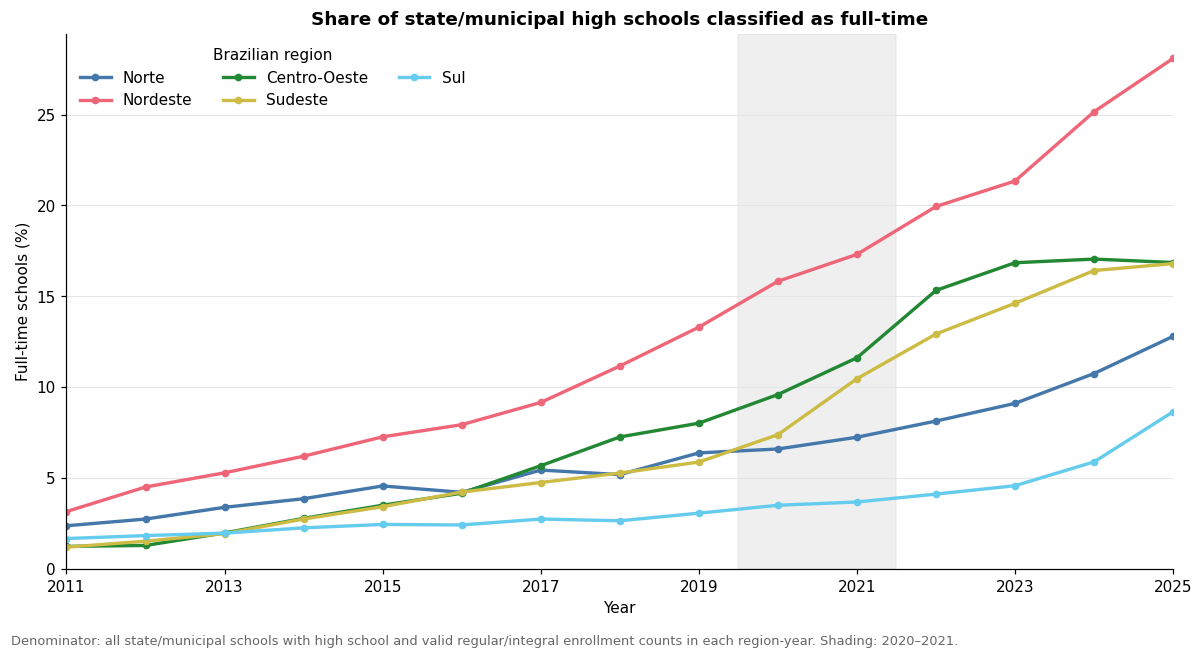

Tabela — percentual de escolas integrais por região e ano:


regiao,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
ano,,,,,
2011,2.4,3.2,1.2,1.2,1.7
2012,2.7,4.5,1.3,1.5,1.8
2013,3.4,5.3,2.0,1.9,2.0
2014,3.9,6.2,2.8,2.7,2.3
2015,4.6,7.3,3.5,3.4,2.4
2016,4.2,7.9,4.2,4.2,2.4
2017,5.4,9.2,5.7,4.8,2.7
2018,5.2,11.2,7.3,5.3,2.7
2019,6.4,13.3,8.0,5.9,3.1


Tabela — número de escolas no denominador por região e ano:


regiao,Norte,Nordeste,Centro-Oeste,Sudeste,Sul
ano,,,,,
2011,1978,6939,2096,11685,4246
2012,2041,6875,2089,11854,4306
2013,2094,6901,2119,11977,4364
2014,2148,6931,2156,12090,4423
2015,2212,6961,2196,12177,4451
2016,2301,7043,2232,12294,4464
2017,2389,7073,2236,12363,4481
2018,2428,7103,2272,12357,4490
2019,2490,7118,2319,12413,4497


In [4]:
expansao = base[
    base["dependencia"].isin(DEPENDENCIAS_EXPANSAO)
    & base["regiao"].notna()
].copy()
expansao["integral"] = expansao["modalidade"].eq("Integral").astype(int)

resumo_expansao = (
    expansao.groupby(["ano", "regiao"], observed=True)
    .agg(
        escolas_em=("escola", "nunique"),
        escolas_integrais=("integral", "sum"),
        proporcao_integral=("integral", "mean"),
    )
    .reset_index()
)
resumo_expansao["proporcao_integral_pct"] = resumo_expansao["proporcao_integral"] * 100

serie_expansao = resumo_expansao.pivot(
    index="ano", columns="regiao", values="proporcao_integral_pct"
).reindex(columns=ORDEM_REGIAO)

fig, ax = plt.subplots(figsize=(11, 5.8))
ax.axvspan(2019.5, 2021.5, color="#dddddd", alpha=0.45, zorder=0)
for regiao in ORDEM_REGIAO:
    if regiao in serie_expansao.columns and serie_expansao[regiao].notna().any():
        ax.plot(
            serie_expansao.index,
            serie_expansao[regiao],
            marker="o", markersize=4, linewidth=2.2,
            color=COR_REGIAO[regiao], label=regiao,
        )
ax.set_title("Share of state/municipal high schools classified as full-time")
ax.set_xlabel("Year")
ax.set_ylabel("Full-time schools (%)")
ax.set_xlim(ANO_INICIAL, ANO_FINAL)
ax.set_xticks(range(ANO_INICIAL, ANO_FINAL + 1, 2))
ax.set_ylim(bottom=0)
ax.legend(title="Brazilian region", ncol=3, loc="upper left")
ax.grid(axis="x", visible=False)
fig.text(
    0.01, -0.02,
    "Denominator: all state/municipal schools with high school and valid regular/integral enrollment counts in each region-year. "
    "Shading: 2020–2021.",
    fontsize=8.5, color="#666666",
)
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "01_expansao_integral_por_regiao.png", bbox_inches="tight")
plt.show()

print("Tabela — percentual de escolas integrais por região e ano:")
display(serie_expansao.round(1))
print("Tabela — número de escolas no denominador por região e ano:")
display(resumo_expansao.pivot(index="ano", columns="regiao", values="escolas_em").reindex(columns=ORDEM_REGIAO))

resumo_expansao.to_csv(PASTA_RESULTADOS / "01_expansao_regional_detalhada.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")
serie_expansao.to_csv(PASTA_RESULTADOS / "01_expansao_regional_percentuais.csv", sep=";", decimal=",", encoding="utf-8-sig")


### Como interpretar

- Linhas crescentes indicam aumento da participação das escolas integrais no conjunto de escolas estaduais/municipais com Ensino Médio daquela região.
- Distâncias entre linhas indicam diferenças na proporção de escolas integrais entre regiões.
- O gráfico descreve expansão proporcional, não o número absoluto de novas escolas.

**Atenção:** se alguma região tiver valores ausentes ou categorias não reconhecidas em `REGIAO`, confira o diagnóstico da seção 0 antes de interpretar as linhas.

---

# 02. School schedules and educational outcomes

**Pergunta:** como as distribuições das taxas de reprovação e abandono diferem entre escolas regulares, mistas e integrais, dentro de cada dependência administrativa?

**Unidade do boxplot:** escola × modalidade observada ao longo de 2011–2025. Para cada escola e modalidade, os quantitativos anuais de aprovação, reprovação e abandono são somados; a taxa acumulada é calculada dividindo a soma de reprovações ou abandonos pela soma de `APR + REP + ABA`.

Se uma escola mudou de modalidade no período, ela pode contribuir com uma unidade em mais de uma modalidade. Por isso, `n` no boxplot representa unidades escola-modalidade, não necessariamente escolas distintas.

O filtro de porte é aplicado à média anual de matrículas regulares + integrais observadas em cada unidade escola-modalidade. O valor padrão é 30.

Unidades escola-modalidade-período antes do filtro: 79.250
Unidades após o filtro: 73.580
Escolas distintas: 33.583

Distribuição por período:


,unidades,escolas
periodo,,
Pré-pandemia,35537,30195
Pós-pandemia,38043,29285


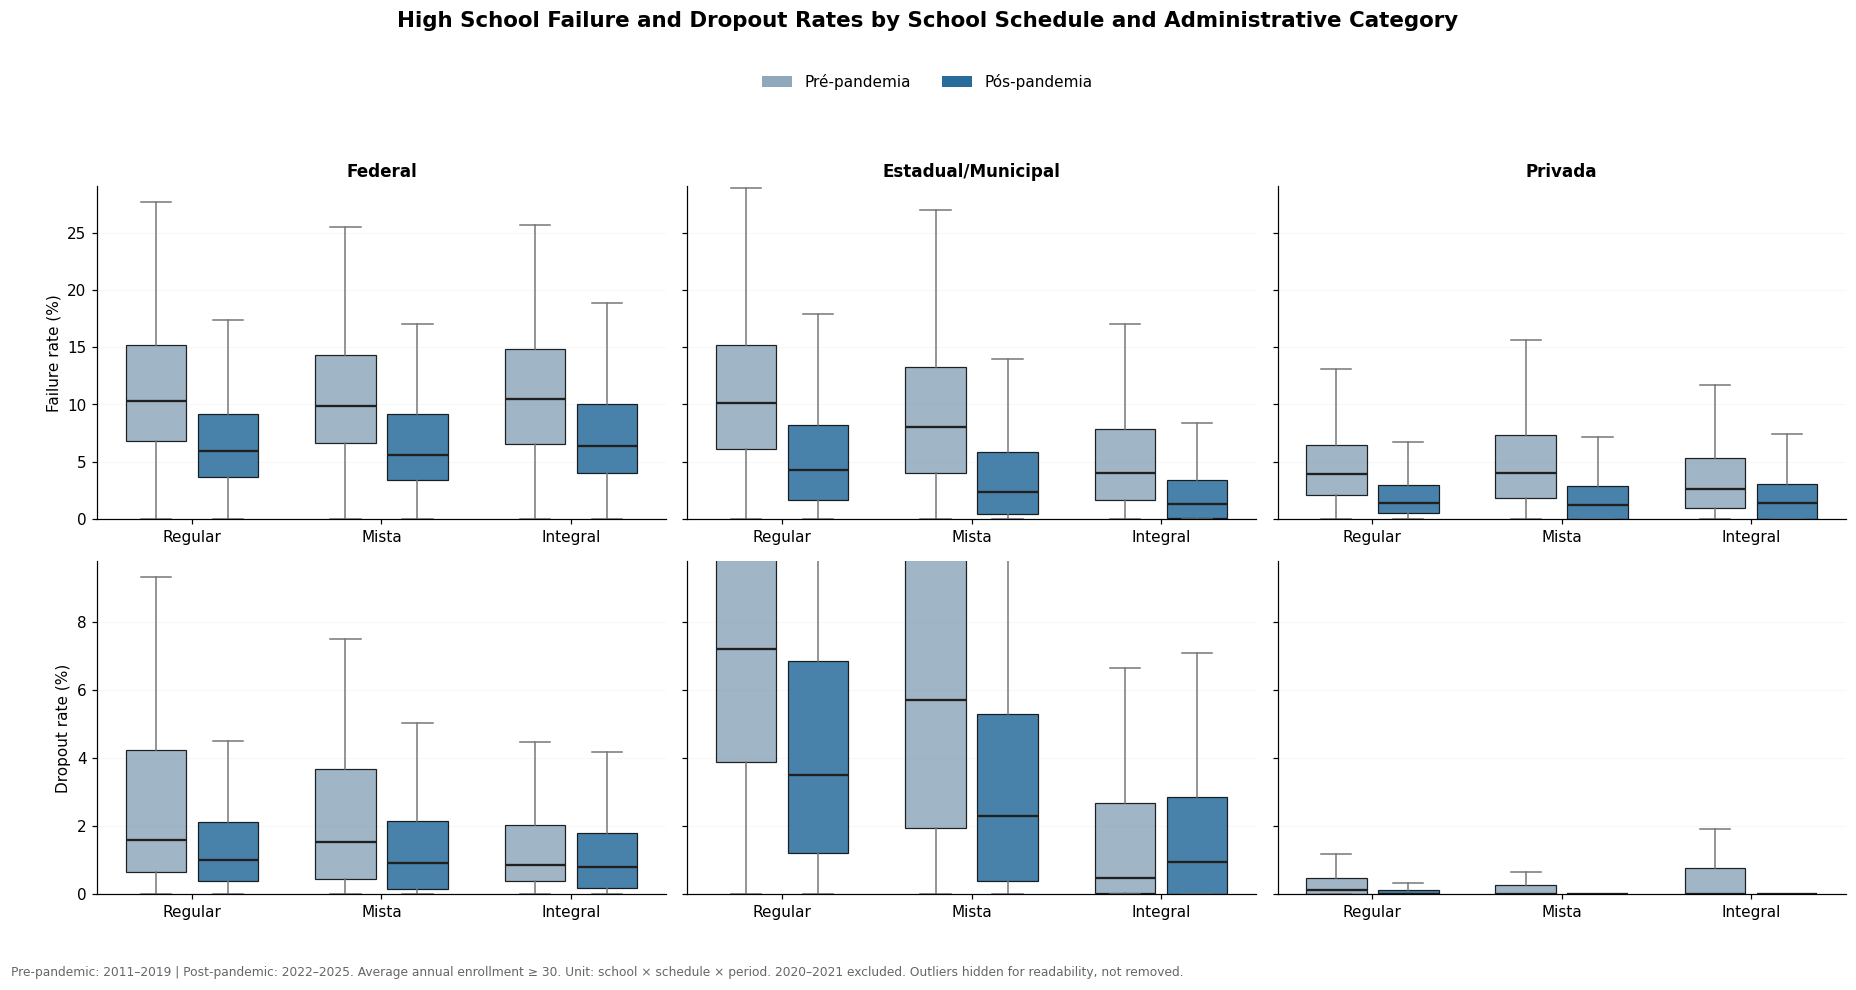

,periodo,dependencia,modalidade,n_unidades,n_escolas,mediana_anos_observados,matriculas_media_mediana,reprovacao_Q1,reprovacao_mediana,reprovacao_Q3,abandono_Q1,abandono_mediana,abandono_Q3
0,Pré-pandemia,Federal,Regular,404,404,6.0,256.02,6.78,10.31,15.16,0.66,1.59,4.24
1,Pré-pandemia,Federal,Mista,148,148,2.0,317.38,6.61,9.89,14.29,0.45,1.53,3.67
2,Pré-pandemia,Federal,Integral,278,278,5.0,242.11,6.54,10.47,14.82,0.38,0.85,2.02
3,Pré-pandemia,Estadual/Municipal,Regular,19888,19888,9.0,267.42,6.07,10.08,15.20,3.87,7.20,11.69
4,Pré-pandemia,Estadual/Municipal,Mista,3426,3426,2.0,291.00,4.03,8.07,13.22,1.94,5.71,10.75
5,Pré-pandemia,Estadual/Municipal,Integral,1839,1839,3.0,249.75,1.64,4.03,7.84,0.02,0.49,2.68
6,Pré-pandemia,Privada,Regular,8746,8746,9.0,87.21,2.11,3.96,6.49,0.00,0.11,0.47
7,Pré-pandemia,Privada,Mista,350,350,2.0,128.75,1.81,4.02,7.35,0.00,0.00,0.26
8,Pré-pandemia,Privada,Integral,458,458,4.0,86.28,0.96,2.58,5.30,0.00,0.00,0.77
9,Pós-pandemia,Federal,Regular,354,354,4.0,355.25,3.67,5.92,9.18,0.40,1.00,2.13



Arquivos exportados com sucesso.


In [10]:

# ============================================================
# BOXPLOTS: REPROVAÇÃO E ABANDONO
# COMPARAÇÃO PRÉ E PÓS-PANDEMIA
# POR MODALIDADE E DEPENDÊNCIA ADMINISTRATIVA
# ============================================================

from matplotlib.patches import Patch

MIN_MEDIA_MATRICULAS_UNIDADE = MIN_MATRICULAS_ANO

# ------------------------------------------------------------
# 1. Definição dos períodos
# ------------------------------------------------------------

ORDEM_PERIODOS = ["Pré-pandemia", "Pós-pandemia"]

CORES_PERIODO = {
    "Pré-pandemia": "#8FA8BC",
    "Pós-pandemia": "#286C9B"
}

rendimento_periodos = rendimento.copy()

rendimento_periodos["ano"] = pd.to_numeric(
    rendimento_periodos["ano"],
    errors="coerce"
)

# Excluímos 2020 e 2021 desta comparação.
condicoes = [
    rendimento_periodos["ano"].between(2011, 2019),
    rendimento_periodos["ano"].between(2022, 2025)
]

rendimento_periodos["periodo"] = np.select(
    condicoes,
    ORDEM_PERIODOS,
    default="Fora do período"
)

rendimento_periodos = rendimento_periodos[
    rendimento_periodos["periodo"].isin(ORDEM_PERIODOS)
].copy()

# ------------------------------------------------------------
# 2. Preparação das variáveis
# ------------------------------------------------------------

COLUNAS_NUMERICAS = [
    "apr", "rep", "abn", "mat_oferta"
]

for c in COLUNAS_NUMERICAS:
    rendimento_periodos[c] = pd.to_numeric(
        rendimento_periodos[c],
        errors="coerce"
    )

# Exigimos os três componentes do rendimento e a matrícula.
rendimento_periodos = rendimento_periodos.dropna(
    subset=[
        "ano",
        "escola",
        "dependencia",
        "modalidade",
        "apr",
        "rep",
        "abn",
        "mat_oferta"
    ]
).copy()

# ------------------------------------------------------------
# 3. Agregação por escola, período e modalidade
# ------------------------------------------------------------

unidades = (
    rendimento_periodos
    .groupby(
        [
            "periodo",
            "escola",
            "dependencia",
            "modalidade"
        ],
        observed=True
    )
    .agg(
        apr_total=("apr", "sum"),
        rep_total=("rep", "sum"),
        abn_total=("abn", "sum"),
        anos_observados=("ano", "nunique"),
        matriculas_media_ano=("mat_oferta", "mean"),
        ano_inicio=("ano", "min"),
        ano_fim=("ano", "max"),
        ano_mediano=("ano", "median")
    )
    .reset_index()
)

# ------------------------------------------------------------
# 4. Cálculo das taxas separadamente
# ------------------------------------------------------------

unidades["den_total"] = (
    unidades["apr_total"]
    + unidades["rep_total"]
    + unidades["abn_total"]
)

# Reprovação
unidades["tx_rep"] = (
    unidades["rep_total"]
    / unidades["den_total"]
    * 100
)

# Abandono
unidades["tx_abn"] = (
    unidades["abn_total"]
    / unidades["den_total"]
    * 100
)

# ------------------------------------------------------------
# 5. Filtro de porte
# ------------------------------------------------------------

n_unidades_antes = len(unidades)

unidades = unidades[
    (unidades["den_total"] > 0)
    & (
        unidades["matriculas_media_ano"]
        >= MIN_MEDIA_MATRICULAS_UNIDADE
    )
].copy()

print(
    f"Unidades escola-modalidade-período antes do filtro: "
    f"{n_unidades_antes:,}".replace(",", ".")
)

print(
    f"Unidades após o filtro: "
    f"{len(unidades):,}".replace(",", ".")
)

print(
    f"Escolas distintas: "
    f"{unidades['escola'].nunique():,}".replace(",", ".")
)

print("\nDistribuição por período:")

display(
    unidades.groupby(
        "periodo",
        observed=True
    ).agg(
        unidades=("escola", "size"),
        escolas=("escola", "nunique")
    )
)

# ------------------------------------------------------------
# 6. Figura: seis painéis (2 × 3)
# ------------------------------------------------------------

fig, axs = plt.subplots(
    2,
    3,
    figsize=(17, 9),
    sharey="row"
)

metricas = [
    ("tx_rep", "Failure rate", "Failure rate (%)"),
    ("tx_abn", "Dropout rate", "Dropout rate (%)")
]

# Deslocamento dos boxplots para comparação dos períodos.
offset = 0.19

for i, (variavel, rotulo, ylabel) in enumerate(metricas):

    for j, dependencia in enumerate(ORDEM_DEPENDENCIA):

        ax = axs[i, j]

        sub = unidades[
            unidades["dependencia"] == dependencia
        ]

        for k, modalidade in enumerate(
            ORDEM_MODALIDADE,
            start=1
        ):

            for periodo, deslocamento in zip(
                ORDEM_PERIODOS,
                [-offset, offset]
            ):

                valores = sub.loc[
                    (sub["modalidade"] == modalidade)
                    & (sub["periodo"] == periodo),
                    variavel
                ].dropna().to_numpy()

                n = len(valores)

                if n == 0:
                    continue

                posicao = k + deslocamento

                bp = ax.boxplot(
                    [valores],
                    positions=[posicao],
                    widths=0.32,
                    patch_artist=True,
                    showfliers=False,
                    whis=1.5,
                    medianprops={
                        "color": "#202020",
                        "linewidth": 1.5
                    },
                    whiskerprops={
                        "color": "#777777",
                        "linewidth": 1.0
                    },
                    capprops={
                        "color": "#777777",
                        "linewidth": 1.0
                    },
                    boxprops={
                        "linewidth": 0.8
                    }
                )

                bp["boxes"][0].set_facecolor(
                    CORES_PERIODO[periodo]
                )

                bp["boxes"][0].set_alpha(0.85)

        # Identificação das modalidades
        ax.set_xticks(
            [1, 2, 3],
            ORDEM_MODALIDADE
        )

        ax.set_xlim(0.5, 3.5)
        ax.set_ylim(bottom=0)

        if i == 0:
            ax.set_title(
                dependencia,
                fontsize=11,
                weight="semibold"
            )

        if j == 0:
            ax.set_ylabel(
                ylabel,
                fontsize=10
            )

        ax.grid(
            axis="y",
            alpha=0.25
        )

        ax.grid(
            axis="x",
            visible=False
        )

# ------------------------------------------------------------
# 7. Títulos e legenda
# ------------------------------------------------------------

fig.suptitle(
    "High School Failure and Dropout Rates by "
    "School Schedule and Administrative Category",
    fontsize=14,
    weight="semibold",
    y=0.99
)

legenda = [
    Patch(
        facecolor=CORES_PERIODO[p],
        label=p
    )
    for p in ORDEM_PERIODOS
]

fig.legend(
    handles=legenda,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.94),
    ncol=2,
    frameon=False
)

fig.text(
    0.01,
    0.015,
    (
        f"Pre-pandemic: 2011–2019 | Post-pandemic: 2022–2025. "
        f"Average annual enrollment ≥ {MIN_MEDIA_MATRICULAS_UNIDADE}. "
        "Unit: school × schedule × period. "
        "2020–2021 excluded. Outliers hidden for readability, not removed."
    ),
    fontsize=8,
    color="#666666"
)

fig.tight_layout(
    rect=[0.02, 0.055, 1, 0.89]
)

fig.savefig(
    PASTA_RESULTADOS
    / "02_boxplots_reprovacao_abandono_pre_pos.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 8. Tabela-resumo dos boxplots
# ------------------------------------------------------------

linhas_resumo = []

for periodo in ORDEM_PERIODOS:

    for dependencia in ORDEM_DEPENDENCIA:

        for modalidade in ORDEM_MODALIDADE:

            s = unidades[
                (unidades["periodo"] == periodo)
                & (unidades["dependencia"] == dependencia)
                & (unidades["modalidade"] == modalidade)
            ]

            registro = {
                "periodo": periodo,
                "dependencia": dependencia,
                "modalidade": modalidade,
                "n_unidades": len(s),
                "n_escolas": s["escola"].nunique(),
                "mediana_anos_observados": (
                    s["anos_observados"].median()
                    if len(s) else np.nan
                ),
                "matriculas_media_mediana": (
                    s["matriculas_media_ano"].median()
                    if len(s) else np.nan
                )
            }

            for variavel, prefixo in [
                ("tx_rep", "reprovacao"),
                ("tx_abn", "abandono")
            ]:

                vals = s[variavel].dropna()

                registro[f"{prefixo}_Q1"] = (
                    vals.quantile(0.25)
                    if len(vals) else np.nan
                )

                registro[f"{prefixo}_mediana"] = (
                    vals.median()
                    if len(vals) else np.nan
                )

                registro[f"{prefixo}_Q3"] = (
                    vals.quantile(0.75)
                    if len(vals) else np.nan
                )

            linhas_resumo.append(registro)

resumo_boxplot = pd.DataFrame(linhas_resumo)

display(
    resumo_boxplot.round(2)
)

# ------------------------------------------------------------
# 9. Exportação das tabelas
# ------------------------------------------------------------

unidades.to_csv(
    PASTA_RESULTADOS
    / "02_unidades_escola_modalidade_periodo.csv",
    sep=";",
    decimal=",",
    index=False,
    encoding="utf-8-sig"
)

resumo_boxplot.to_csv(
    PASTA_RESULTADOS
    / "02_resumo_boxplots_pre_pos.csv",
    sep=";",
    decimal=",",
    index=False,
    encoding="utf-8-sig"
)

print("\nArquivos exportados com sucesso.")


### Como interpretar e limitações dos boxplots

- A linha dentro da caixa é a mediana; a caixa vai do primeiro ao terceiro quartil (AIQ = Q3 − Q1).
- Os bigodes seguem a convenção de 1,5 × AIQ. Os marcadores de outliers estão ocultos para reduzir a poluição visual; as observações não foram removidas do cálculo.
- A mediana é uma medida de centro da distribuição das unidades escola-modalidade. Ela não representa a taxa de um aluno médio do Brasil.
- Uma escola que mudou de modalidade pode aparecer em mais de uma categoria. As unidades de escolas integrais podem cobrir anos mais recentes do que as unidades regulares. A tabela de apoio inclui `ano_mediano_das_unidades` para revelar essa diferença temporal.
- Diferenças entre distribuições são descritivas e não demonstram que a modalidade causou as diferenças observadas.

---

# 03. Does the association vary across administrative categories and years?

**Pergunta:** a associação entre a proporção de matrículas integrais da escola (`p_int`) e as taxas de reprovação e abandono varia entre dependências administrativas e anos?

**Método:** calcular o coeficiente de Spearman separadamente em cada combinação de ano e dependência administrativa. `p_int` é mantida como variável contínua; não transformamos Regular, Mista e Integral em números ordinais para essa análise.

\[
\rho_{d,t}=\operatorname{Spearman}(p_{int},\, taxa)
\]

em que `d` representa a dependência administrativa e `t` representa o ano. A análise é feita entre escolas do mesmo ano e da mesma dependência, evitando misturar diretamente anos com tendências gerais diferentes.

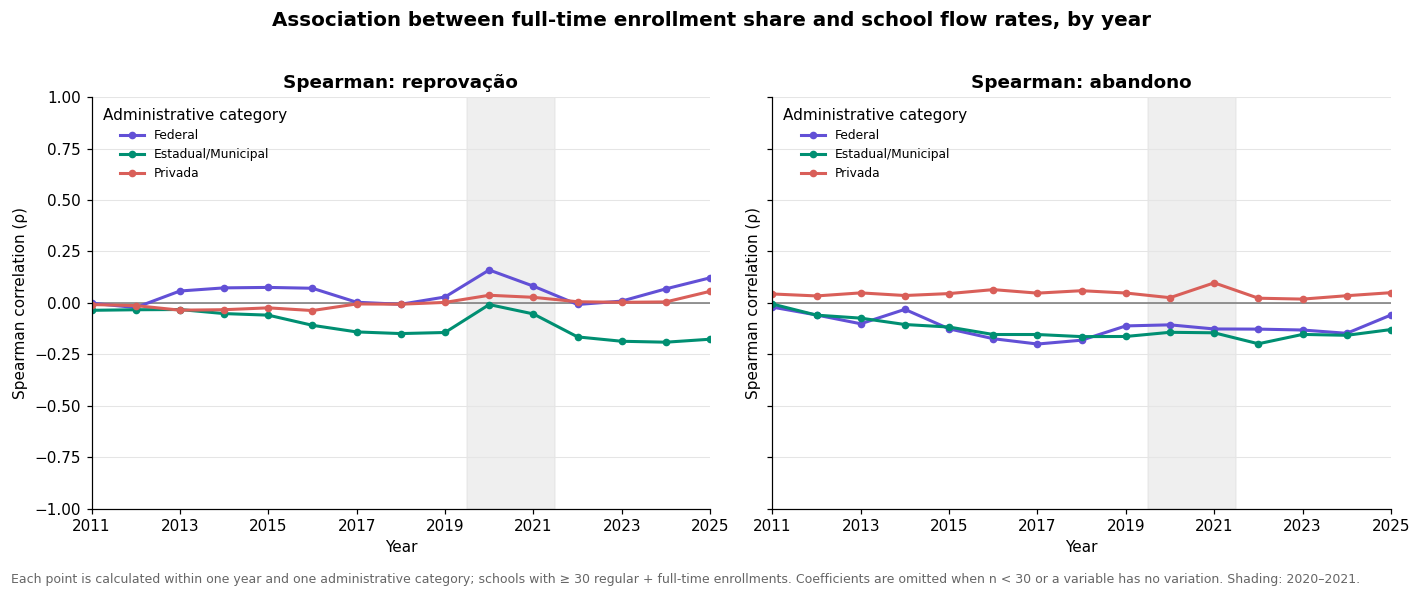

Tabela longa com n, rho e p-valor (o tamanho e a direção de rho são o foco descritivo):


,ano,dependencia,taxa,n_escolas,rho_spearman,p_valor
0,2011,Federal,Reprovação,302,-0.0013,0.9814
1,2011,Federal,Abandono,302,-0.0203,0.7250
2,2012,Federal,Reprovação,339,-0.0224,0.6806
3,2012,Federal,Abandono,339,-0.0585,0.2824
4,2013,Federal,Reprovação,381,0.0579,0.2595
...,...,...,...,...,...,...
85,2023,Privada,Abandono,7424,0.0186,0.1090
86,2024,Privada,Reprovação,7604,0.0050,0.6660
87,2024,Privada,Abandono,7604,0.0351,0.0022
88,2025,Privada,Reprovação,7618,0.0564,0.0000


Coeficientes de Spearman por ano:


dependencia Estadual/Municipal             Federal             Privada  \
taxa                  Abandono Reprovação Abandono Reprovação Abandono   
ano                                                                      
2011                    -0.005     -0.036   -0.020     -0.001    0.044   
2012                    -0.059     -0.033   -0.059     -0.022    0.034   
2013                    -0.074     -0.032   -0.101      0.058    0.049   
2014                    -0.105     -0.052   -0.031      0.073    0.036   
2015                    -0.117     -0.059   -0.126      0.075    0.045   
2016                    -0.153     -0.109   -0.174      0.071    0.065   
2017                    -0.153     -0.141   -0.200      0.003    0.048   
2018                    -0.164     -0.149   -0.181     -0.007    0.059   
2019                    -0.163     -0.144   -0.112      0.029    0.048   
2020                    -0.143     -0.008   -0.106      0.160    0.026   
2021                    -0.145     -0.053   -0.127      0.082    0.098   
2022                    -0.198     -0.165   -0.127     -0.008    0.023   
2023                    -0.153     -0.186   -0.132      0.009    0.019   
2024                    -0.157     -0.191   -0.148      0.068    0.035   
2025                    -0.129     -0.176   -0.059      0.122    0.050   

dependencia             
taxa        Reprovação  
ano                     
2011            -0.008  
2012            -0.013  
2013            -0.035  
2014            -0.033  
2015            -0.024  
2016            -0.037  
2017            -0.005  
2018            -0.006  
2019             0.003  
2020             0.037  
2021             0.027  
2022             0.006  
2023             0.003  
2024             0.005  
2025             0.056

Tamanhos amostrais por ano e dependência:


dependencia Estadual/Municipal             Federal             Privada  \
taxa                  Abandono Reprovação Abandono Reprovação Abandono   
ano                                                                      
2011                     18426      18426      302        302     6656   
2012                     18430      18430      339        339     6997   
2013                     18528      18528      381        381     7171   
2014                     18646      18646      393        393     7260   
2015                     18825      18825      451        451     7246   
2016                     18946      18946      493        493     7301   
2017                     19107      19107      539        539     7323   
2018                     19166      19166      571        571     7219   
2019                     19161      19161      584        584     7210   
2020                     19136      19136      541        541     7183   
2021                     19324      19324      570        570     7199   
2022                     19350      19350      595        595     7337   
2023                     19463      19463      610        610     7424   
2024                     19520      19520      623        623     7604   
2025                     19692      19692      623        623     7618   

dependencia             
taxa        Reprovação  
ano                     
2011              6656  
2012              6997  
2013              7171  
2014              7260  
2015              7246  
2016              7301  
2017              7323  
2018              7219  
2019              7210  
2020              7183  
2021              7199  
2022              7337  
2023              7424  
2024              7604  
2025              7618

In [6]:
def calcular_spearman_seguro(sub, variavel, minimo_n=MIN_N_SPEARMAN):
    dados = sub[["p_int", variavel]].replace([np.inf, -np.inf], np.nan).dropna()
    n = len(dados)
    if n < minimo_n:
        return n, np.nan, np.nan
    if dados["p_int"].nunique() < 2 or dados[variavel].nunique() < 2:
        return n, np.nan, np.nan
    resultado = stats.spearmanr(dados["p_int"], dados[variavel])
    return n, float(resultado.statistic), float(resultado.pvalue)


base_correlacao = rendimento[
    rendimento["dependencia"].notna()
    & (rendimento["mat_oferta"] >= MIN_MATRICULAS_ANO)
].copy()

registros = []
for dependencia in ORDEM_DEPENDENCIA:
    sub_dep = base_correlacao[base_correlacao["dependencia"] == dependencia]
    for ano in sorted(sub_dep["ano"].dropna().unique()):
        sub_ano = sub_dep[sub_dep["ano"] == ano]
        for variavel, rotulo in [("tx_rep", "Reprovação"), ("tx_abn", "Abandono")]:
            n, rho, pvalor = calcular_spearman_seguro(sub_ano, variavel)
            registros.append({
                "ano": int(ano), "dependencia": dependencia, "taxa": rotulo,
                "n_escolas": n, "rho_spearman": rho, "p_valor": pvalor,
            })

spearman_anual = pd.DataFrame(registros)

fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, taxa in zip(axs, ["Reprovação", "Abandono"]):
    ax.axvspan(2019.5, 2021.5, color="#dddddd", alpha=0.45, zorder=0)
    ax.axhline(0, color="#777777", linewidth=1)
    dados_taxa = spearman_anual[spearman_anual["taxa"] == taxa]
    for dependencia in ORDEM_DEPENDENCIA:
        s = dados_taxa[dados_taxa["dependencia"] == dependencia].sort_values("ano")
        if s["rho_spearman"].notna().any():
            ax.plot(
                s["ano"], s["rho_spearman"], marker="o", markersize=4,
                linewidth=2, color=COR_DEPENDENCIA[dependencia], label=dependencia,
            )
    ax.set_title(f"Spearman: {taxa.lower()}")
    ax.set_xlabel("Year")
    ax.set_xlim(ANO_INICIAL, ANO_FINAL)
    ax.set_xticks(range(ANO_INICIAL, ANO_FINAL + 1, 2))
    ax.set_ylim(-1, 1)
    ax.set_ylabel("Spearman correlation (ρ)")
    ax.grid(axis="x", visible=False)
    ax.legend(title="Administrative category", fontsize=8)
fig.suptitle("Association between full-time enrollment share and school flow rates, by year", y=1.02, fontsize=13, weight="semibold")
fig.text(
    0.01, -0.02,
    f"Each point is calculated within one year and one administrative category; schools with ≥ {MIN_MATRICULAS_ANO} regular + full-time enrollments. "
    f"Coefficients are omitted when n < {MIN_N_SPEARMAN} or a variable has no variation. Shading: 2020–2021.",
    fontsize=8.2, color="#666666",
)
fig.tight_layout()
fig.savefig(PASTA_RESULTADOS / "03_spearman_anual_por_dependencia.png", bbox_inches="tight")
plt.show()

print("Tabela longa com n, rho e p-valor (o tamanho e a direção de rho são o foco descritivo):")
display(spearman_anual.round(4))

rho_largo = spearman_anual.pivot_table(
    index="ano", columns=["dependencia", "taxa"], values="rho_spearman", aggfunc="first"
)
n_largo = spearman_anual.pivot_table(
    index="ano", columns=["dependencia", "taxa"], values="n_escolas", aggfunc="first"
)
print("Coeficientes de Spearman por ano:")
display(rho_largo.round(3))
print("Tamanhos amostrais por ano e dependência:")
display(n_largo)

spearman_anual.to_csv(PASTA_RESULTADOS / "03_spearman_anual_detalhado.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")
rho_largo.to_csv(PASTA_RESULTADOS / "03_spearman_anual_coeficientes.csv", sep=";", decimal=",", encoding="utf-8-sig")
n_largo.to_csv(PASTA_RESULTADOS / "03_spearman_anual_tamanhos_amostrais.csv", sep=";", decimal=",", encoding="utf-8-sig")


### Como interpretar

- `ρ < 0`: escolas com maior proporção de matrículas integrais tendem a apresentar taxas menores naquele ano e dependência.
- `ρ > 0`: escolas com maior proporção de matrículas integrais tendem a apresentar taxas maiores.
- `ρ` próximo de zero: não há associação monotônica clara na amostra daquele ano e dependência.
- Compare a magnitude e a estabilidade dos coeficientes ao longo dos anos; não use apenas o p-valor. Com amostras grandes, associações pequenas também podem produzir p-valores muito baixos.

Calcular a correlação dentro de cada ano reduz a mistura causada por tendências temporais comuns, mas **não controla** outras diferenças entre escolas (por exemplo, localização, porte, perfil dos estudantes ou contexto socioeconômico). Associação não é causalidade.

---

# 04. Exportação e checklist final

As três figuras e as tabelas de apoio são salvas em `03. Resultados/Poster_3_analises`, na raiz do projeto.

In [7]:
arquivos_gerados = sorted(p.name for p in PASTA_RESULTADOS.iterdir() if p.is_file())
print("Arquivos gerados:")
for nome in arquivos_gerados:
    print(" -", nome)

print("\nChecklist antes de usar no pôster:")
print("1. Conferir os valores originais e padronizados de DEP_ADM e REGIAO na seção 0.")
print("2. Confirmar com a equipe os limiares de 10% e 90% da modalidade.")
print("3. Confirmar que a expansão deve ficar restrita às redes Estadual/Municipal.")
print("4. Conferir se os denominadores e os totais APR + REP + ABA fazem sentido para os anos analisados.")
print("5. Ler a tabela de anos medianos das unidades escola-modalidade antes de comparar os boxplots.")
print("6. Interpretar Spearman como associação, nunca como efeito causal.")


Arquivos gerados:
 - 01_expansao_integral_por_regiao.png
 - 01_expansao_regional_detalhada.csv
 - 01_expansao_regional_percentuais.csv
 - 02_boxplots_reprovacao_abandono_por_dependencia.png
 - 02_resumo_boxplots.csv
 - 02_unidades_escola_modalidade.csv
 - 03_spearman_anual_coeficientes.csv
 - 03_spearman_anual_detalhado.csv
 - 03_spearman_anual_por_dependencia.png
 - 03_spearman_anual_tamanhos_amostrais.csv

Checklist antes de usar no pôster:
1. Conferir os valores originais e padronizados de DEP_ADM e REGIAO na seção 0.
2. Confirmar com a equipe os limiares de 10% e 90% da modalidade.
3. Confirmar que a expansão deve ficar restrita às redes Estadual/Municipal.
4. Conferir se os denominadores e os totais APR + REP + ABA fazem sentido para os anos analisados.
5. Ler a tabela de anos medianos das unidades escola-modalidade antes de comparar os boxplots.
6. Interpretar Spearman como associação, nunca como efeito causal.
